# Lab 03 Activity: Transfer Learning

**CCSFEN1L Software Engineering | #SL03 Transfer Learning for Image Classification**  

Work in **pairs**. You will fine-tune a pretrained ResNet-18 on a small image dataset, train the same architecture from scratch for comparison, analyze the errors, and save the model. Lab 09 (Track A) attacks the model you save today.

Select a GPU runtime first: **Runtime > Change runtime type**.

**Runtime:** Colab GPU (CPU works with fewer epochs)  
**Time:** Tasks 1 to 5, about 3 hours

## Get the data
Use a small dataset organized in folders, one folder per class, with at most about 300 images per class, for example `data/train/healthy/` and `data/train/early_blight/`, plus the same classes under `data/val/`. Use a licensed public plant-disease dataset or another dataset your instructor approves.

**Option A:** upload a zip of your folders to Colab and unzip it:
```
!unzip -q my_dataset.zip -d data
```
**Option B (fallback):** set `USE_CIFAR = True` to build a small CIFAR-10 subset in the same layout.

In [1]:
USE_CIFAR = True     # set to True only if you have no dataset yet

In [2]:
import os
from torchvision.datasets import CIFAR10

def cifar_to_folders(root, classes, n_train, n_val):
    """Write a small CIFAR-10 subset as root/train/<class>/*.png and root/val/<class>/*.png."""
    cifar = CIFAR10("cifar", train=True, download=True)
    wanted = {cifar.class_to_idx[c]: c for c in classes}
    seen = {c: 0 for c in classes}
    for img, label in cifar:
        if label not in wanted:
            continue
        name = wanted[label]
        k = seen[name]
        if k >= n_train + n_val:
            continue
        split = "train" if k < n_train else "val"
        os.makedirs(f"{root}/{split}/{name}", exist_ok=True)
        img.save(f"{root}/{split}/{name}/{k}.png")
        seen[name] += 1
        if all(v >= n_train + n_val for v in seen.values()):
            break

if USE_CIFAR:
    cifar_to_folders("data", ["airplane", "bird", "ship"], n_train=300, n_val=100)

## Task 1: Data loaders (30 minutes)

In [3]:
import torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
weights = models.ResNet18_Weights.DEFAULT
mean, std = weights.transforms().mean, weights.transforms().std

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder("data/train", transform=train_tf)
val_ds   = datasets.ImageFolder("data/val",   transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=64, num_workers=2)
print(train_ds.classes, len(train_ds), len(val_ds))

['airplane', 'bird', 'ship'] 900 300


Augmentation (random crops and flips) is applied only to training data. Validation images are resized and cropped the same way every time. How many images per class do you have, and is the dataset balanced?

**Answer:** _Write your answer here._

## Task 2: A training loop (30 minutes)

In [4]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = nn.functional.cross_entropy(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, epochs, lr):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    history = []
    for ep in range(epochs):
        tr = run_epoch(model, train_dl, opt)
        va = run_epoch(model, val_dl)
        history.append((tr, va))
        print(f"epoch {ep+1}: train acc {tr[1]:.3f} | val acc {va[1]:.3f}")
    return history

## Task 3: Transfer learning versus training from scratch (75 minutes)
Both models use the same data, epochs, and learning rate. The timer records each model's training time.

In [5]:
import time
EPOCHS = 8            # reduce to 3 on a CPU runtime
n_classes = len(train_ds.classes)

# 1) Pretrained ResNet-18: fine-tune the last block and a new classifier head
tl = models.resnet18(weights=weights)
for name, p in tl.named_parameters():
    p.requires_grad = name.startswith("layer4") or name.startswith("fc")
tl.fc = nn.Linear(tl.fc.in_features, n_classes)
tl = tl.to(device)
t0 = time.time(); hist_tl = train(tl, epochs=EPOCHS, lr=1e-3); time_tl = time.time() - t0

# 2) Same architecture, random initialization, all layers trained
scratch = models.resnet18(weights=None, num_classes=n_classes).to(device)
t0 = time.time(); hist_sc = train(scratch, epochs=EPOCHS, lr=1e-3); time_sc = time.time() - t0
print(f"Training time: transfer {time_tl:.0f} s | scratch {time_sc:.0f} s")

epoch 1: train acc 0.668 | val acc 0.800
epoch 2: train acc 0.762 | val acc 0.793
epoch 3: train acc 0.800 | val acc 0.860
epoch 4: train acc 0.846 | val acc 0.863
epoch 5: train acc 0.814 | val acc 0.840
epoch 6: train acc 0.828 | val acc 0.830
epoch 7: train acc 0.820 | val acc 0.880
epoch 8: train acc 0.863 | val acc 0.890
epoch 1: train acc 0.476 | val acc 0.477
epoch 2: train acc 0.526 | val acc 0.573
epoch 3: train acc 0.551 | val acc 0.510
epoch 4: train acc 0.549 | val acc 0.510
epoch 5: train acc 0.566 | val acc 0.590
epoch 6: train acc 0.533 | val acc 0.573
epoch 7: train acc 0.589 | val acc 0.610
epoch 8: train acc 0.558 | val acc 0.637
Training time: transfer 185 s | scratch 174 s


Plot validation accuracy and loss per epoch for both models on the same axes.

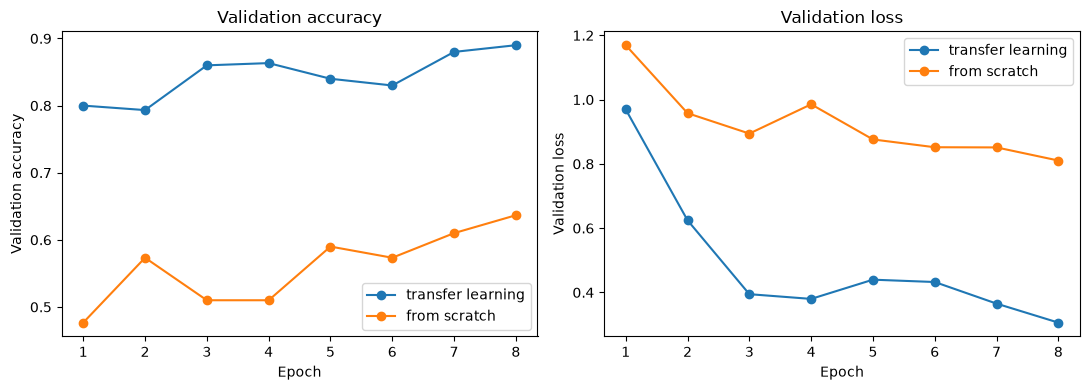

In [6]:
import matplotlib.pyplot as plt

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))
for hist, label in [(hist_tl, "transfer learning"), (hist_sc, "from scratch")]:
    epochs = range(1, len(hist) + 1)
    ax_acc.plot(epochs, [va[1] for _, va in hist], marker="o", label=label)
    ax_loss.plot(epochs, [va[0] for _, va in hist], marker="o", label=label)
ax_acc.set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy")
ax_loss.set(xlabel="Epoch", ylabel="Validation loss", title="Validation loss")
ax_acc.legend(); ax_loss.legend()
plt.tight_layout(); plt.show()

Compute macro F1 on the validation set for both models.

In [7]:
from sklearn.metrics import f1_score, classification_report

def predict_all(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps += model(x.to(device)).argmax(1).cpu().tolist(); ys += y.tolist()
    return ys, ps

for model, label in [(tl, "transfer learning"), (scratch, "from scratch")]:
    ys, ps = predict_all(model, val_dl)
    print(f"{label:18s} macro F1 = {f1_score(ys, ps, average='macro'):.3f}")
print(classification_report(*predict_all(tl, val_dl), target_names=train_ds.classes, digits=3))

transfer learning  macro F1 = 0.890
from scratch       macro F1 = 0.621
              precision    recall  f1-score   support

    airplane      0.857     0.900     0.878       100
        bird      0.926     0.880     0.903       100
        ship      0.890     0.890     0.890       100

    accuracy                          0.890       300
   macro avg      0.891     0.890     0.890       300
weighted avg      0.891     0.890     0.890       300



What do the curves, the training times, and the macro F1 scores tell you? Why does the pretrained model need fewer epochs?

**Answer:** _Write your answer here._

## Task 4: Error analysis (30 minutes)
Collect the validation images the transfer-learning model got wrong and display at least three with their true and predicted labels.

33 of 300 validation images are misclassified


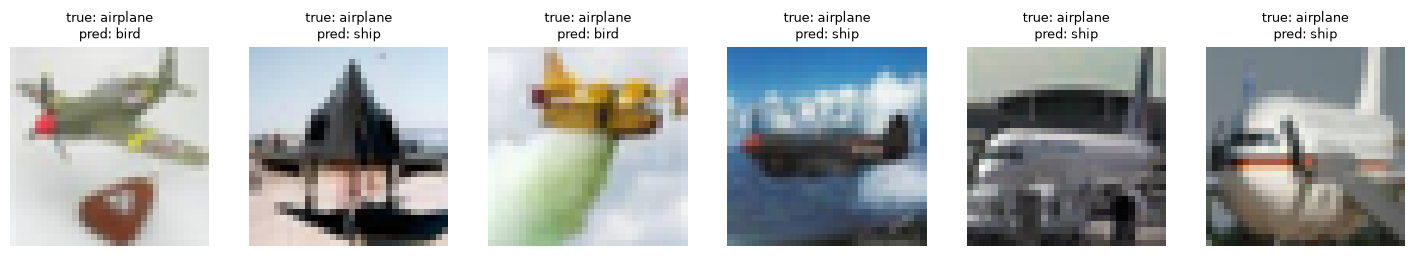

In [8]:
from PIL import Image

ys, ps = predict_all(tl, val_dl)
wrong = [(path, t, p) for (path, _), t, p in zip(val_ds.samples, ys, ps) if t != p]
print(len(wrong), "of", len(ys), "validation images are misclassified")

show = wrong[:6]
fig, axes = plt.subplots(1, max(len(show), 1), figsize=(3 * max(len(show), 1), 3.2), squeeze=False)
for ax, (path, t, p) in zip(axes[0], show):
    ax.imshow(Image.open(path)); ax.axis("off")
    ax.set_title(f"true: {val_ds.classes[t]}\npred: {val_ds.classes[p]}", fontsize=9)
plt.show()

For one of them, propose a specific likely cause: a blurry photo, a background the model may be using as a shortcut, two visually similar classes, or a wrong label. How could you check it?

**Answer:** _Write your answer here._

## Task 5: Save the model (10 minutes)

In [9]:
import os
os.makedirs("labs/lab03", exist_ok=True)
torch.save(tl.state_dict(), "labs/lab03/resnet18_finetuned.pt")
print("Saved. Download it or copy it to your repository; Lab 09 Track A loads it.")

Saved. Download it or copy it to your repository; Lab 09 Track A loads it.


**Troubleshooting:** *CUDA out of memory:* reduce `batch_size` to 16 or 8 and restart the runtime. *Validation accuracy stuck near 1 / number of classes:* check that labels match folders, the learning rate, and the normalization. *Training accuracy near 100% but validation much lower:* overfitting; add augmentation, train fewer epochs, or freeze more layers. *`num_workers` errors on Windows:* set `num_workers=0` locally.

## Thesis reflection (3:30 to 4:00)
Add an entry to `TOPIC_BANK.md` in your team repository, using what you measured today.

```
## Lab 03: Deep learning and computer vision  (date)
Idea: <one-sentence thesis idea>
Problem it addresses: <who has the problem, and what is the gap?>
Closest existing work: <one or two sources you found>
Data needed: <source, size, license, how we would get it>
Compute needed: <Colab / laptop / simulator / device>
Biggest risk: <the one thing most likely to make it fail>
Team interest (1-5): <score>    Feasibility (1-5): <score>
```

## Before you submit
Save this notebook to `labs/lab03/` in your team repository, then run **Runtime > Restart session and run all** to check that it runs from top to bottom.

- [ ] Augmentation is applied to training data only.
- [ ] Both models use the same data, epochs, and learning rate.
- [ ] The plot labels both axes and both models.
- [ ] The error analysis names a specific, checkable cause.

---
*CCSFEN1L Software Engineering laboratory notebooks · Shared under CC BY-NC-ND 4.0.*